In [1]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Path:", path)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Path: /kaggle/input/asl-alphabet
Using Colab cache for faster access to the 'asl-alphabet' dataset.
Path: /kaggle/input/asl-alphabet


In [2]:
import os, random, shutil

# cari folder yang berisi subfolder 'A'
train_dir = None
for root, dirs, files in os.walk(path):
    if "A" in dirs and "B" in dirs:
        train_dir = root
        break
print("Train dir:", train_dir)

SUBSET_DIR = "/content/asl_subset"
N_PER_CLASS = 500
random.seed(42)

if os.path.exists(SUBSET_DIR):
    shutil.rmtree(SUBSET_DIR)

classes = sorted(os.listdir(train_dir))
for c in classes:
    src = os.path.join(train_dir, c)
    dst = os.path.join(SUBSET_DIR, c)
    os.makedirs(dst, exist_ok=True)
    imgs = os.listdir(src)
    for f in random.sample(imgs, min(N_PER_CLASS, len(imgs))):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))

print(len(classes), "kelas:", classes)

Train dir: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
29 kelas: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [9]:
import numpy as np
from sklearn.model_selection import train_test_split

raw_ds = tf.keras.utils.image_dataset_from_directory(
    SUBSET_DIR, image_size=IMG_SIZE, batch_size=64, shuffle=False
)
class_names = raw_ds.class_names

X = np.concatenate([x.numpy() for x, _ in raw_ds]).astype("uint8")
y = np.concatenate([l.numpy() for _, l in raw_ds])

# 70 / 15 / 15, proporsi tiap kelas dijaga sama
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=42)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds = make_ds(X_val, y_val)
test_ds = make_ds(X_test, y_test)

print("Train/Val/Test:", len(X_train), len(X_val), len(X_test))

Found 14500 files belonging to 29 classes.
Train/Val/Test: 10150 2175 2175


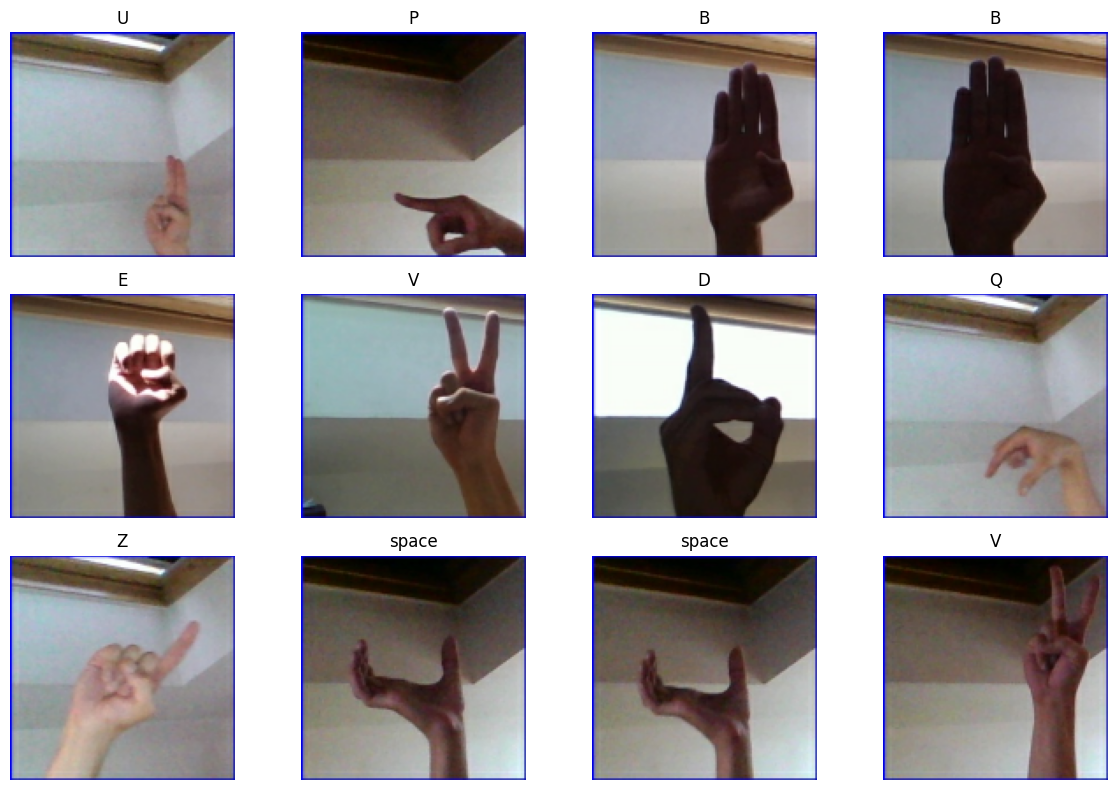

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
for images, labels in full_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [11]:
from tensorflow.keras import layers, models

NUM_CLASSES = len(class_names)

cnn_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    # augmentasi ringan (aktif hanya saat training)
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="cnn_scratch")

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_model.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,291,421 (16.37 MB)

 Trainable params: 4,291,421 (16.37 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

start = time.time()
history_cnn = cnn_model.fit(
    train_ds, validation_data=val_ds,
    epochs=25, callbacks=[early_stop]
)
cnn_time = time.time() - start
print(f"Waktu training CNN: {cnn_time/60:.1f} menit")

Epoch 1/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.1186 - loss: 3.0950 - val_accuracy: 0.3278 - val_loss: 2.1867
Epoch 2/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.4485 - loss: 1.7726 - val_accuracy: 0.6602 - val_loss: 1.0669
Epoch 3/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.6500 - loss: 1.0828 - val_accuracy: 0.7936 - val_loss: 0.6506
Epoch 4/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7413 - loss: 0.7910 - val_accuracy: 0.8492 - val_loss: 0.4550
Epoch 5/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7999 - loss: 0.6093 - val_accuracy: 0.8809 - val_loss: 0.3756
Epoch 6/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8315 - loss: 0.5083 - val_accuracy: 0.8768 - val_loss: 0.3879
Epoch 7/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8550 - loss: 0.4373 - val_accuracy: 0.9057 - val_loss: 0.2790
Epoch 8/25
318/318 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8761 - loss: 0.3721 - val_acc

In [13]:
test_loss, test_acc = cnn_model.evaluate(test_ds)
print(f"CNN Test Accuracy: {test_acc:.4f}")

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9577 - loss: 0.1348
CNN Test Accuracy: 0.9577


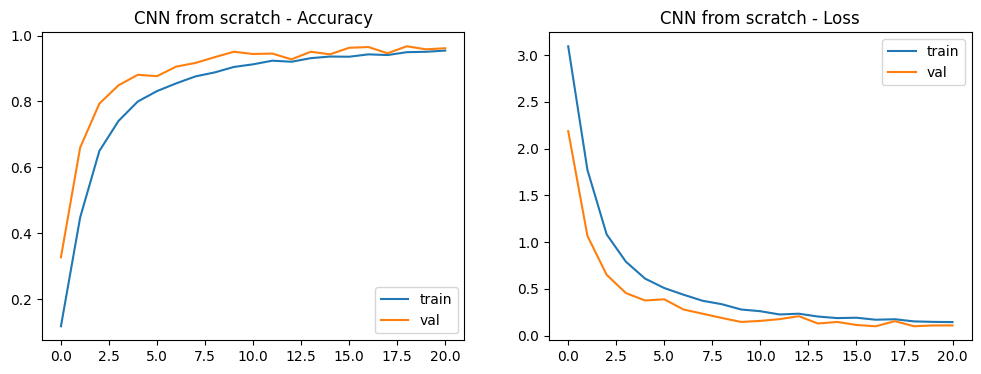

In [14]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title(f"{title} - Loss"); ax[1].legend()
    plt.show()

plot_history(history_cnn, "CNN from scratch")

In [15]:
base = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3), include_top=False, weights="imagenet"
)
base.trainable = False  # bekukan "mata"-nya

tl_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # augmentasi sama dengan CNN supaya perbandingan adil
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),

    # MobileNetV2 butuh piksel di rentang [-1, 1]
    layers.Rescaling(1./127.5, offset=-1),

    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="mobilenetv2_tl")

tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_3               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 29)             │        37,149 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,295,133 (8.76 MB)

 Trainable params: 37,149 (145.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
early_stop_tl = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

start = time.time()
history_tl = tl_model.fit(
    train_ds, validation_data=val_ds,
    epochs=15, callbacks=[early_stop_tl]
)
tl_time = time.time() - start
print(f"Waktu training Transfer Learning: {tl_time/60:.1f} menit")

Epoch 1/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.4963 - loss: 1.7770 - val_accuracy: 0.8464 - val_loss: 0.5958
Epoch 2/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.7598 - loss: 0.7994 - val_accuracy: 0.9016 - val_loss: 0.3766
Epoch 3/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8250 - loss: 0.5956 - val_accuracy: 0.9103 - val_loss: 0.3003
Epoch 4/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8446 - loss: 0.5135 - val_accuracy: 0.9182 - val_loss: 0.2627
Epoch 5/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8620 - loss: 0.4555 - val_accuracy: 0.9297 - val_loss: 0.2483
Epoch 6/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8715 - loss: 0.4085 - val_accuracy: 0.9310 - val_loss: 0.2203
Epoch 7/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.8739 - loss: 0.3906 - val_accuracy: 0.9421 - val_loss: 0.1990
Epoch 8/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.8833 - loss: 0.3689 - val_acc

68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9439 - loss: 0.1925
Transfer Learning Test Accuracy: 0.9439


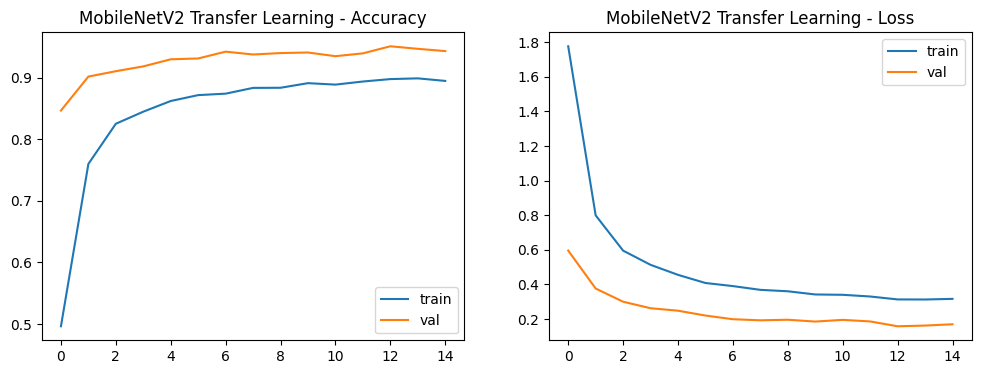

In [17]:
tl_loss, tl_acc = tl_model.evaluate(test_ds)
print(f"Transfer Learning Test Accuracy: {tl_acc:.4f}")

plot_history(history_tl, "MobileNetV2 Transfer Learning")

Epoch 1/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9154 - loss: 0.2566 - val_accuracy: 0.9540 - val_loss: 0.1456
Epoch 2/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9357 - loss: 0.1970 - val_accuracy: 0.9508 - val_loss: 0.1420
Epoch 3/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9418 - loss: 0.1736 - val_accuracy: 0.9549 - val_loss: 0.1319
Epoch 4/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 11s 35ms/step - accuracy: 0.9485 - loss: 0.1525 - val_accuracy: 0.9641 - val_loss: 0.1063
Epoch 5/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9588 - loss: 0.1305 - val_accuracy: 0.9605 - val_loss: 0.1255
Epoch 6/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.9565 - loss: 0.1277 - val_accuracy: 0.9531 - val_loss: 0.1409
Epoch 7/15
318/318 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - accuracy: 0.9624 - loss: 0.1091 - val_accuracy: 0.9655 - val_loss: 0.1124
Waktu fine-tuning: 1.4 menit
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9632 - 

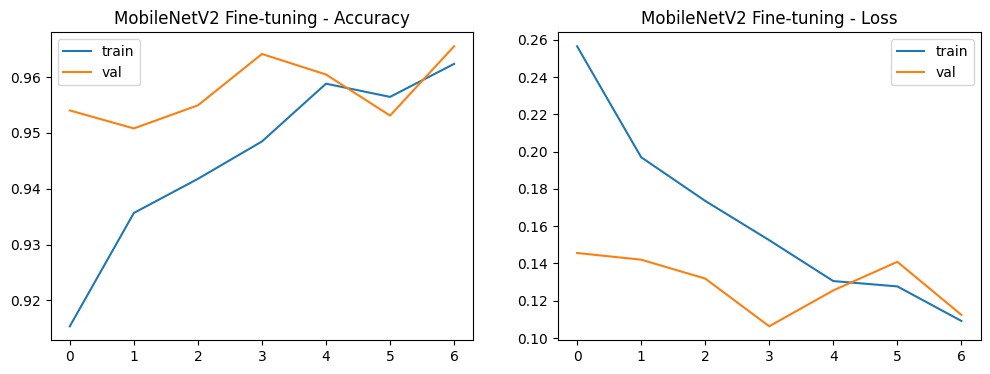

In [18]:
# buka 30 layer terakhir MobileNetV2
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

# BatchNorm tetap beku supaya statistiknya tidak rusak
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# WAJIB compile ulang setelah mengubah trainable, dan pakai LR kecil
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

start = time.time()
history_ft = tl_model.fit(
    train_ds, validation_data=val_ds,
    epochs=15, callbacks=[early_stop_ft]
)
ft_time = time.time() - start
print(f"Waktu fine-tuning: {ft_time/60:.1f} menit")

ft_loss, ft_acc = tl_model.evaluate(test_ds)
print(f"Fine-tuned Test Accuracy: {ft_acc:.4f}")

plot_history(history_ft, "MobileNetV2 Fine-tuning")

68/68 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step


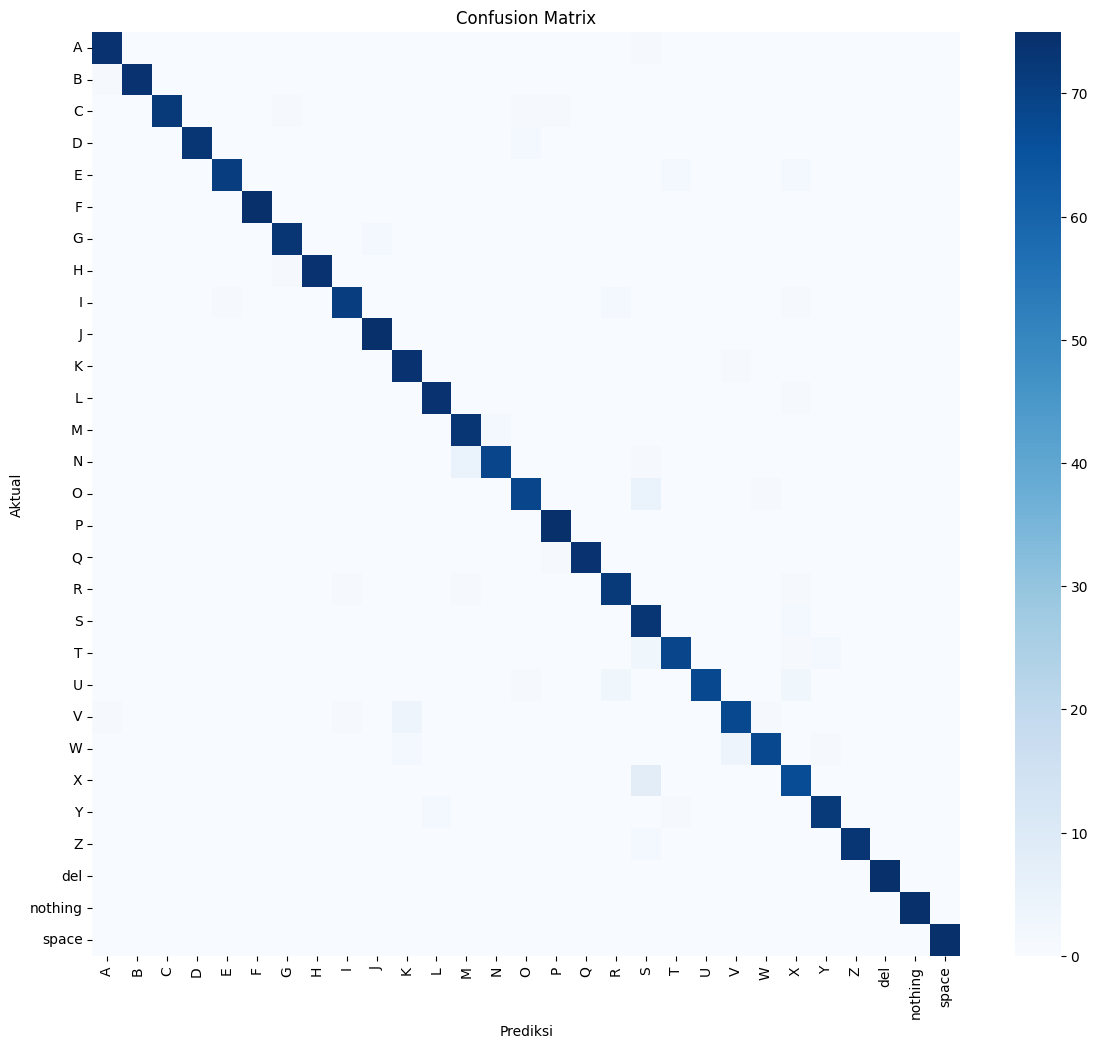

              precision    recall  f1-score   support

           A       0.97      0.99      0.98        75
           B       1.00      0.99      0.99        75
           C       1.00      0.96      0.98        75
           D       1.00      0.97      0.99        75
           E       0.99      0.95      0.97        75
           F       1.00      1.00      1.00        75
           G       0.97      0.97      0.97        75
           H       1.00      0.99      0.99        75
           I       0.97      0.95      0.96        75
           J       0.97      1.00      0.99        75
           K       0.93      0.99      0.95        75
           L       0.97      0.99      0.98        75
           M       0.92      0.97      0.95        75
           N       0.97      0.92      0.95        75
           O       0.95      0.92      0.93        75
           P       0.97      1.00      0.99        75
           Q       1.00      0.99      0.99        75
           R       0.94    

In [19]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# ganti ke cnn_model jika CNN yang terbaik
best_model = tl_model

y_pred = np.argmax(best_model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds])

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

In [20]:
import pandas as pd

hasil = pd.DataFrame({
    "Model": ["CNN from scratch", "MobileNetV2 (frozen)", "MobileNetV2 + fine-tuning"],
    "Test Accuracy": [0.9577, 0.9439, ft_acc],
    "Waktu training (menit)": [round(cnn_time/60, 1), round(tl_time/60, 1), round(ft_time/60, 1)],
})
print(hasil.to_string(index=False))


                    Model  Test Accuracy  Waktu training (menit)
         CNN from scratch       0.957700                     2.6
     MobileNetV2 (frozen)       0.943900                     2.2
MobileNetV2 + fine-tuning       0.963218                     1.4
